# Simulación multiactivo con Cholesky
María Fernanda Gómez Flores
Simulación de Procesos Financieros

AAPL, MSFT y NVDA. Capital inicial de $100,000, 10,000 simulaciones y horizonte de 1 año.

In [46]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

### 1. Precios y rendimientos
Descargamos los precios del último año y calculamos los rendimientos logarítmicos.

In [47]:
tickers = ["AAPL", "MSFT", "NVDA"]
prices = yf.download(tickers=tickers, period="1y")["Close"]
prices = prices[tickers].dropna()
rets = np.log(prices / prices.shift(1)).dropna()
rets.head()

/var/folders/x9/60hcc2ln62d3r3xyv90d3wl40000gn/T/ipykernel_12833/1368230215.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  prices = yf.download(tickers=tickers, period="1y")["Close"]
[*********************100%***********************]  3 of 3 completed


Ticker,AAPL,MSFT,NVDA
Date,,,
2025-11-13,-0.001904,-0.015477,-0.036467
2025-11-14,-0.001980,0.013597,0.017559
2025-11-17,-0.018338,-0.005287,-0.018951
2025-11-18,-0.000075,-0.027367,-0.028483
2025-11-19,0.004179,-0.013600,0.028054


### 2. Correlación y covarianza
Calculamos la correlación y la matriz de covarianzas para tomar en cuenta la relación entre las tres acciones.

In [48]:
R = rets.corr()
Sigma = rets.cov()*252
print(R)
print(Sigma)

Ticker      AAPL      MSFT      NVDA
Ticker                              
AAPL    1.000000  0.155491  0.059994
MSFT    0.155491  1.000000  0.233442
NVDA    0.059994  0.233442  1.000000
Ticker      AAPL      MSFT      NVDA
Ticker                              
AAPL    0.062696  0.013119  0.005809
MSFT    0.013119  0.113541  0.030416
NVDA    0.005809  0.030416  0.149516


### 3. Cholesky
Descomponemos la matriz de covarianzas para generar números normales correlacionados.

In [49]:
L = np.linalg.cholesky(Sigma)
L

array([[0.25039213, 0.        , 0.        ],
       [0.05239413, 0.33286042, 0.        ],
       [0.02319788, 0.08772569, 0.37587509]])

### 4. Rendimiento y volatilidad
Calculamos el rendimiento promedio y la volatilidad anual con 252 días bursátiles.

In [50]:
mu = rets.mean() * 252
vol = rets.std() * np.sqrt(252)

print("Rendimiento anual:")
print((mu * 100).round(2))
print("Volatilidad anual:")
print((vol * 100).round(2))

Rendimiento anual:
Ticker
AAPL    26.75
MSFT     2.78
NVDA   -10.78
dtype: float64
Volatilidad anual:
Ticker
AAPL    25.04
MSFT    33.70
NVDA    38.67
dtype: float64


### 5. Simulación
Generamos 10,000 números normales usando la semilla 67 y los transformamos con Cholesky.

In [51]:
M = 10000
np.random.seed(67)
epsilon = np.random.normal(0, 1, (3, M))
Z = L @ epsilon
Z.T

array([[ 0.28257307,  0.09875733,  0.16957867],
       [ 0.03610461, -0.18365856,  0.34843934],
       [-0.27925198,  0.25368223,  0.44317262],
       ...,
       [ 0.18799901, -0.02800524,  0.00138938],
       [-0.48151403, -0.21928965,  0.08517005],
       [-0.1667416 ,  0.32397919,  0.84479396]])

### 6. Precios futuros
Simulamos los precios de las acciones dentro de un año. La volatilidad ya está incorporada en Z por la matriz de covarianzas.

In [52]:
T = 1
S0 = prices.iloc[-1].values
ST = S0 * np.exp((mu.values - 0.5 * vol.values**2) * T + np.sqrt(T) * Z.T)
ST = pd.DataFrame(ST, columns=tickers)
ST.head()

,AAPL,MSFT,NVDA
0,597.441411,558.780463,171.491927
1,466.933928,421.298148,205.079326
2,340.641692,652.415455,225.457156
3,612.977066,342.300905,121.413106
4,433.268646,406.538990,130.214751


### 7. Pesos de los portafolios
Calculamos el valor final usando los tres vectores de pesos que vimos en clase.

In [53]:
V0 = 100000
pesos = {
    "Escenario 1": [1, 0, 0],
    "Escenario 2": [0.33, 0.33, 0.34],
    "Escenario 3": [0.2, 0.2, 0.6]
}

resultados = {}

for nombre, w in pesos.items():
    VT = V0 * np.sum((ST.values / S0) * w, axis=1)
    PnL = VT - V0
    resultados[nombre] = {"VT": VT, "PnL": PnL}

    print(nombre)
    print(f"Valor final promedio: ${np.mean(VT):,.2f}")
    print(f"Ganancia promedio: ${np.mean(PnL):,.2f}")
    print()

Escenario 1
Valor final promedio: $130,613.26
Ganancia promedio: $30,613.26

Escenario 2
Valor final promedio: $107,601.63
Ganancia promedio: $7,601.63

Escenario 3
Valor final promedio: $100,732.80
Ganancia promedio: $732.80



### 8. Gráfica del valor final
Comparamos los valores futuros de los tres portafolios antes de restar los $100,000.

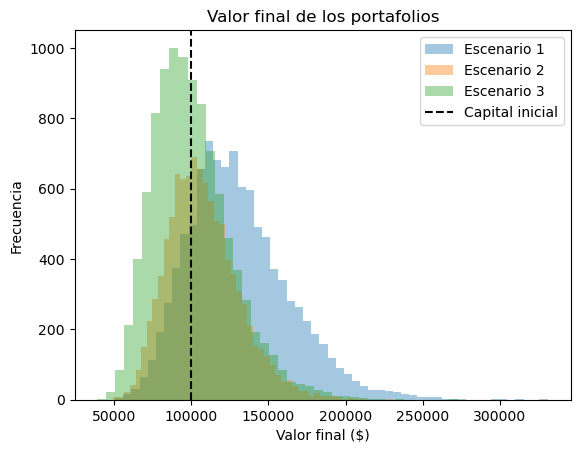

In [54]:
for nombre, datos in resultados.items():
    plt.hist(datos["VT"], bins=50, alpha=0.4, label=nombre)

plt.axvline(V0, color="black", linestyle="--", label="Capital inicial")
plt.xlabel("Valor final ($)")
plt.ylabel("Frecuencia")
plt.title("Valor final de los portafolios")
plt.legend()
plt.show()

### 9. Ganancias y pérdidas
Al valor final le restamos el capital inicial. Los resultados menores que cero son pérdidas.

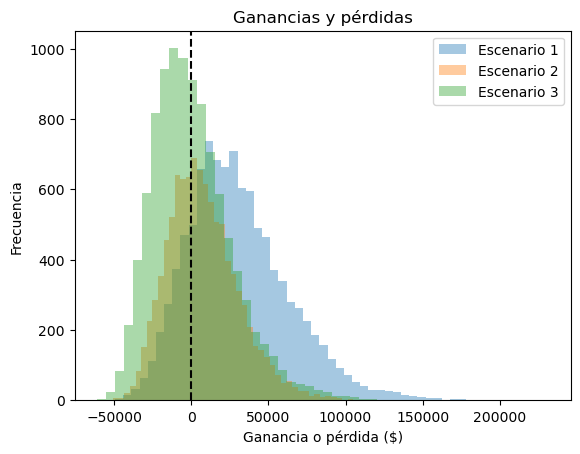

In [55]:
for nombre, datos in resultados.items():
    plt.hist(datos["PnL"], bins=50, alpha=0.4, label=nombre)

plt.axvline(0, color="black", linestyle="--")
plt.xlabel("Ganancia o pérdida ($)")
plt.ylabel("Frecuencia")
plt.title("Ganancias y pérdidas")
plt.legend()
plt.show()

### 10. VaR y CVaR
Calculamos el VaR al 95% con el percentil 5 y el CVaR con el promedio de los resultados que quedan debajo de ese percentil.

In [56]:
for nombre, datos in resultados.items():
    PnL = datos["PnL"]
    q = np.percentile(PnL, 5)
    VaR = -q
    CVaR = -np.mean(PnL[PnL <= q])

    print(nombre)
    print("VaR 95%:", round(VaR, 2))
    print("CVaR 95%:", round(CVaR, 2))
    print()

Escenario 1
VaR 95%: 15991.84
CVaR 95%: 23963.82

Escenario 2
VaR 95%: 25608.07
CVaR 95%: 31321.88

Escenario 3
VaR 95%: 34401.58
CVaR 95%: 40046.36



### 11. Cuartiles
Calculamos Q1, Q2 y Q3 de las ganancias y pérdidas de cada portafolio, que corresponden a los percentiles 25, 50 y 75.

In [57]:
for nombre, datos in resultados.items():
    PnL = datos["PnL"]
    Q1 = np.percentile(PnL, 25)
    Q2 = np.percentile(PnL, 50)
    Q3 = np.percentile(PnL, 75)

    print(nombre)
    print(f"Q1: ${Q1:,.2f}")
    print(f"Q2: ${Q2:,.2f}")
    print(f"Q3: ${Q3:,.2f}")
    print()

Escenario 1
Q1: $7,353.76
Q2: $26,468.21
Q3: $49,585.17

Escenario 2
Q1: $-8,648.47
Q2: $5,141.37
Q3: $21,223.10

Escenario 3
Q1: $-17,668.22
Q2: $-2,764.48
Q3: $15,103.60



### 12. Gráficas de VaR, CVaR y cuartiles
En cada portafolio marcamos el VaR, CVaR y los tres cuartiles en una misma gráfica para poder compararlos.

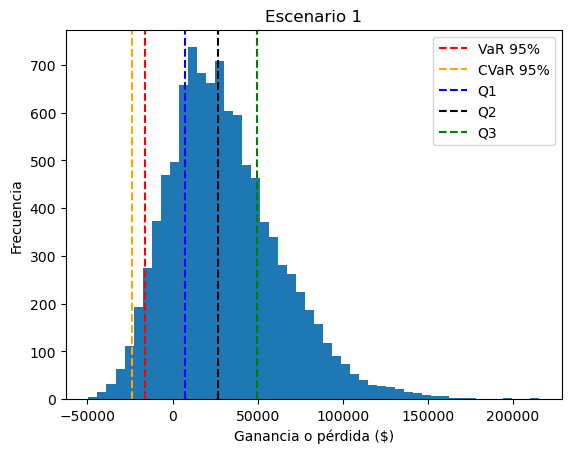

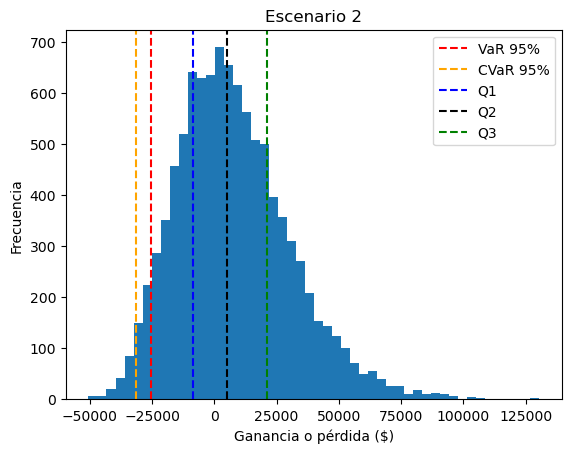

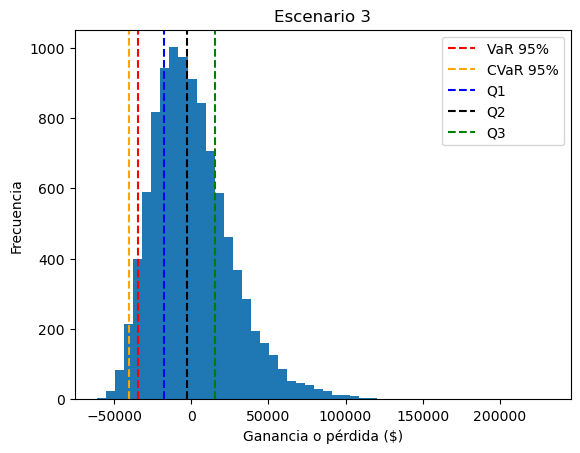

In [58]:
for nombre, datos in resultados.items():
    PnL = datos["PnL"]
    q = np.percentile(PnL, 5)
    cvar = np.mean(PnL[PnL <= q])
    Q1 = np.percentile(PnL, 25)
    Q2 = np.percentile(PnL, 50)
    Q3 = np.percentile(PnL, 75)

    plt.hist(PnL, bins=50)
    plt.axvline(q, color="red", linestyle="--", label="VaR 95%")
    plt.axvline(cvar, color="orange", linestyle="--", label="CVaR 95%")
    plt.axvline(Q1, color="blue", linestyle="--", label="Q1")
    plt.axvline(Q2, color="black", linestyle="--", label="Q2")
    plt.axvline(Q3, color="green", linestyle="--", label="Q3")
    plt.axvline(np.mean(PnL), color="purple", linestyle="--", label="Media")
    plt.xlabel("Ganancia o pérdida ($)")
    plt.ylabel("Frecuencia")
    plt.title(nombre)
    plt.legend()
    plt.show()

### Conclusiones
Con Cholesky simulamos los precios de AAPL, MSFT y NVDA tomando en cuenta la covarianza entre sus rendimientos. Después calculamos el valor final de los tres portafolios con diferentes pesos y les restamos el capital inicial para obtener las ganancias o pérdidas.

Al cambiar los pesos también cambia la distribución de resultados de cada portafolio. Con los cuartiles podemos ver cómo se distribuyen las ganancias y pérdidas, mientras que el VaR al 95% marca el límite del 5% de los resultados más bajos y el CVaR nos dice cuál es el promedio dentro de esa parte de la distribución.

Las gráficas nos permiten comparar los tres escenarios y ver que no basta con revisar el valor final promedio, también hay que tomar en cuenta las posibles pérdidas.